In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [2]:

# 1. Download and get the folder path
handle = "chethuhn/network-intrusion-dataset"
download_path = kagglehub.dataset_download(handle)

# 2. Get the list of all CSV files in that folder
files = [f for f in os.listdir(download_path) if f.endswith('.csv')]
print(f"Found {len(files)} files. Starting the merge...")

# 3. Loop through and load each file into a list
dataframes = []
for file_name in files:
    print(f"Loading: {file_name}")
    temp_df = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        handle=handle,
        path=file_name,
    )
    
    # ---> STRIP SPACES RIGHT HERE <---
    temp_df.columns = temp_df.columns.str.strip()
    
    dataframes.append(temp_df)

# 4. "Glue" them all together into one massive DataFrame
df = pd.concat(dataframes, ignore_index=True)

print("\n" + "="*50)
print("DATASET STRUCTURE & SUMMARY STATISTICS")
print("="*50)
print(f"Total rows: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

print("\n--- Dataset Info (Δομή και Τύποι Δεδομένων) ---")
# df.info() prints directly to the console
df.info(show_counts=True)

print("\n--- Summary Statistics (Στατιστική Περιγραφή) ---")
# Transposing (.T) makes it much easier to read when you have 70+ columns
summary_stats = df.describe().round(3).T
print(summary_stats)

Found 8 files. Starting the merge...
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

DATASET STRUCTURE & SUMMARY STATISTICS
Total rows: 2830743
Total columns: 79

--- Dataset Info (Δομή και Τύποι Δεδομένων) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   Destination Port             2830743 non-null  int64  
 1   Flow Duration                2830743 non-null  int64  
 2   Total Fwd Packets            2830743 non-

**Heatmap function**

In [3]:
def plot_correlation_heatmap(data, title="Correlation Heatmap"):
    """Generates a lower-triangle heatmap anchored from 0 to 1."""
    plt.figure(figsize=(20, 16))
    
    corr = data.select_dtypes(include=[np.number]).corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    
    sns.heatmap(corr, 
                mask=mask, 
                cmap='coolwarm', 
                vmin=0, vmax=1,  # Restored to your original preference
                linewidths=0.5, 
                linecolor='white', 
                cbar_kws={"shrink": .8})
    
    plt.title(title, fontsize=18)
    plt.xticks(fontsize=10, rotation=90)
    plt.yticks(fontsize=10, rotation=0)
    plt.tight_layout()
    plt.show()

1. BEFORE CLEANING
Generating heatmap for raw dataset...


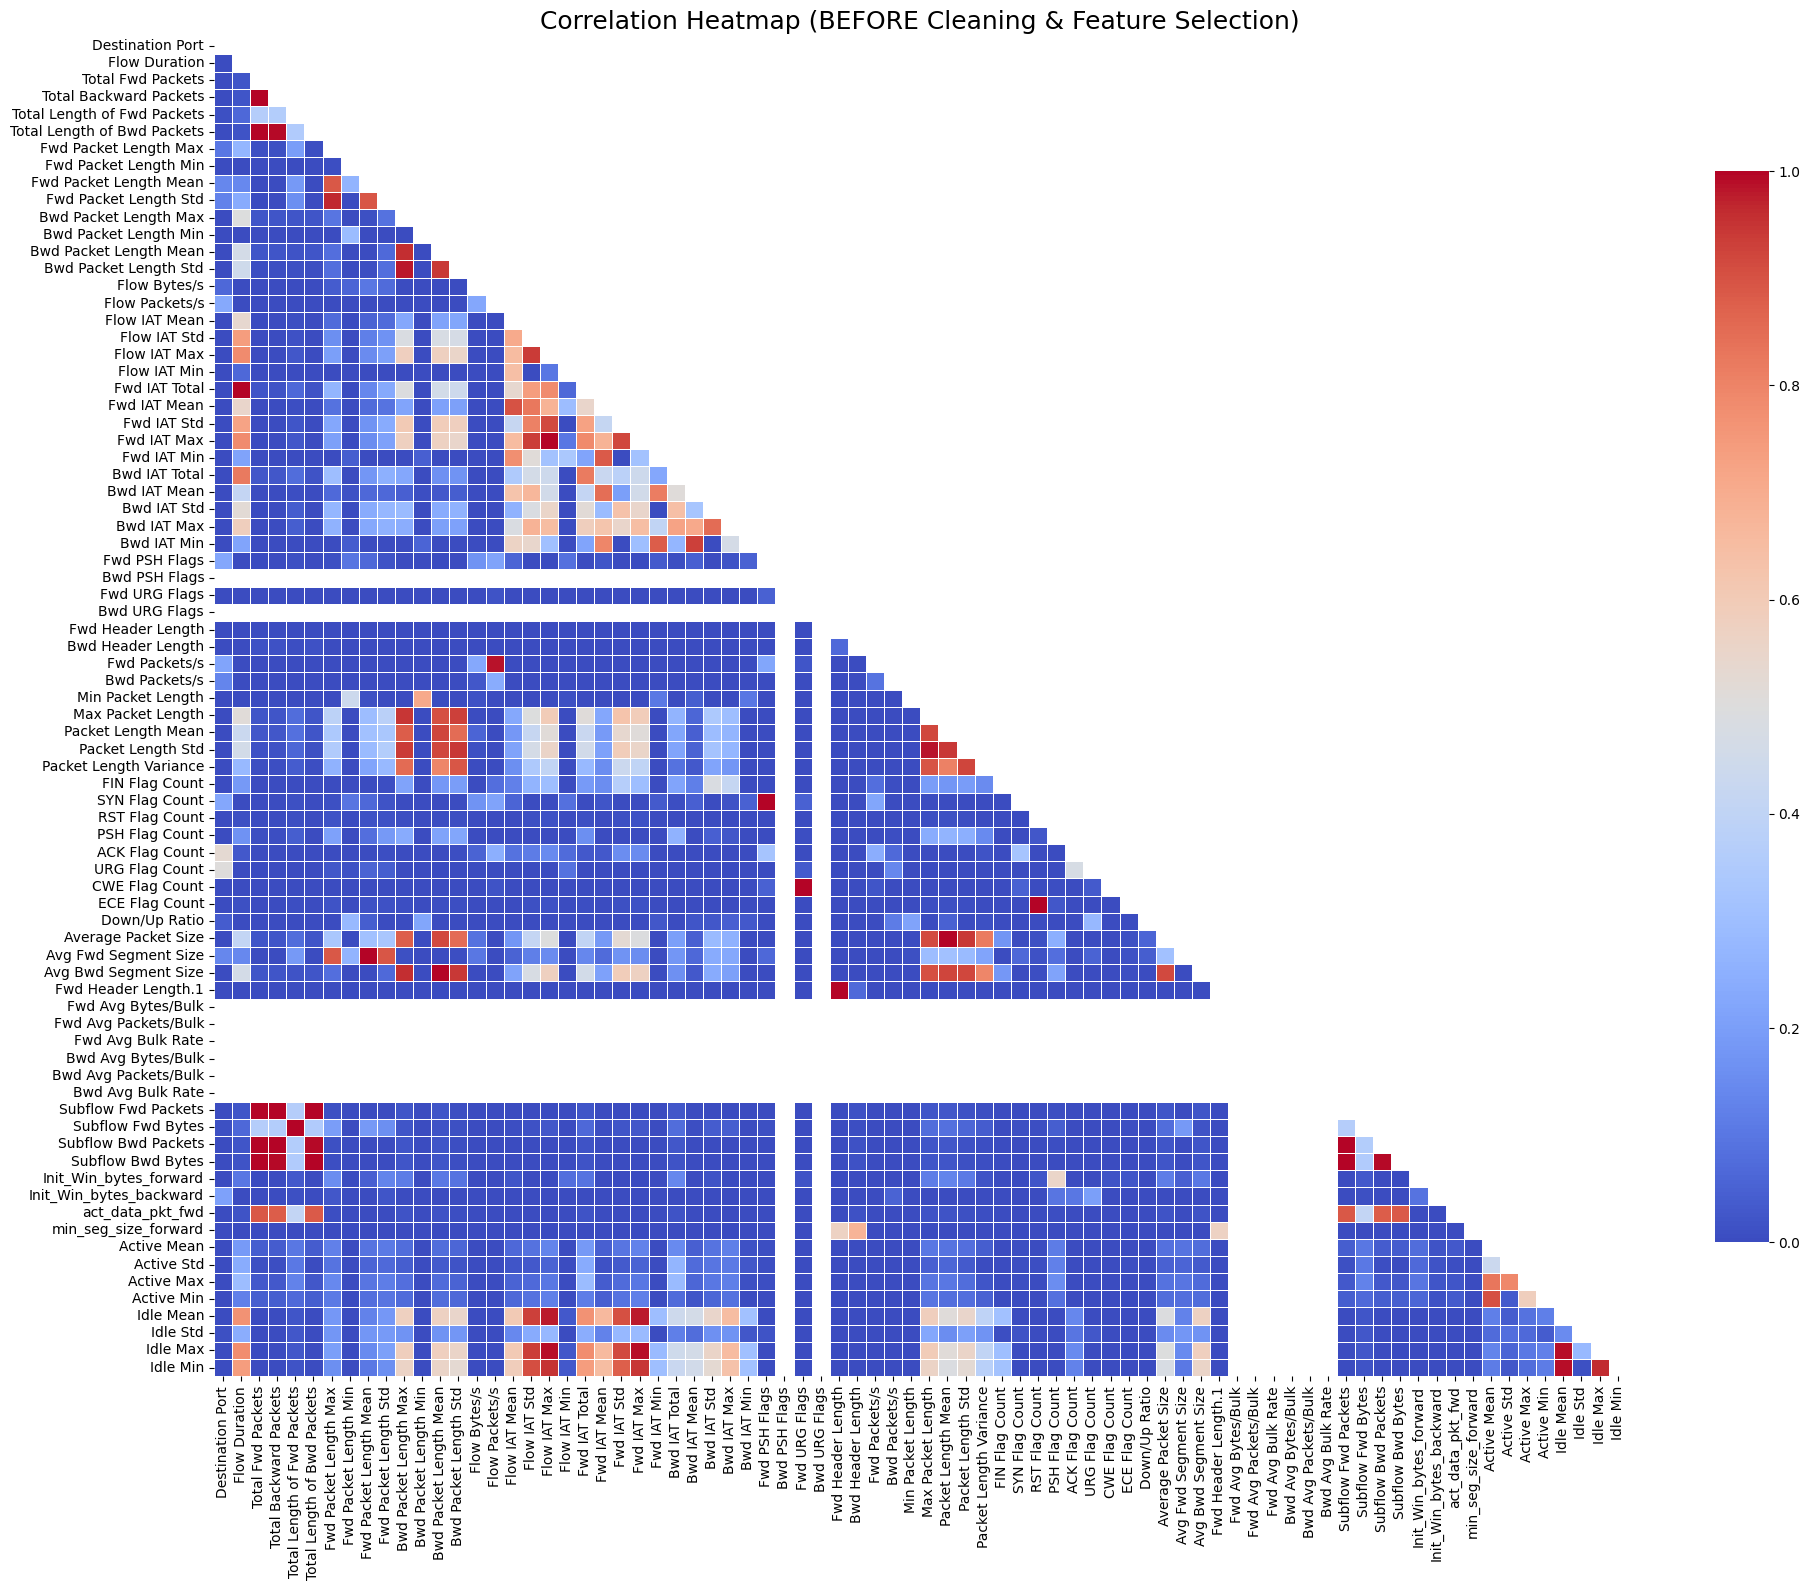

In [4]:
print("1. BEFORE CLEANING")
print("Generating heatmap for raw dataset...")

# Note: This might take a minute because df has ~2.8 million rows
plot_correlation_heatmap(df, title="Correlation Heatmap (BEFORE Cleaning & Feature Selection)")

In [5]:
print("2. CLEANING DATA...")
initial_shape = df.shape

# 1. Handle Infs and NaNs
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# 2. Handle Duplicates
df.drop_duplicates(inplace=True)

print("\n3. Data Sanity Checks (Strict Negative Value Removal)...")
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Columns where -1 is a valid placeholder (e.g., UDP flows)
allowed_negative_cols = ['Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'min_seg_size_forward']

for col in numeric_cols:
    if col in allowed_negative_cols:
        # Keep >= -1, drop anything less than -1 (e.g., -2, -100000)
        invalid_mask = df[col] < -1
    else:
        # Keep >= 0, drop ALL negatives
        invalid_mask = df[col] < 0
        
    invalid_count = invalid_mask.sum()
    if invalid_count > 0:
        print(f"    - Εντοπίστηκαν {invalid_count} μη έγκυρες αρνητικές τιμές στη στήλη '{col}'. Διαγράφονται.")
        df = df[~invalid_mask] # Keep only rows that are NOT invalid

print(f"Shape after strict cleaning: {df.shape}")

print("\n3. FEATURE SELECTION (Dropping Highly Correlated Columns)...")
threshold = 0.90

# Calculate correlation matrix using absolute values
corr_matrix = df.select_dtypes(include=[np.number]).corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find columns to drop
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > threshold)]

# Drop them and save to our final dataframe
df_cleaned = df.drop(columns=to_drop)

print(f"Removed {len(to_drop)} columns with correlation > {threshold}.")
print(f"Final dataset shape: {df_cleaned.shape}")

2. CLEANING DATA...

3. Data Sanity Checks (Strict Negative Value Removal)...
    - Εντοπίστηκαν 107 μη έγκυρες αρνητικές τιμές στη στήλη 'Flow Duration'. Διαγράφονται.
    - Εντοπίστηκαν 2773 μη έγκυρες αρνητικές τιμές στη στήλη 'Flow IAT Min'. Διαγράφονται.
    - Εντοπίστηκαν 35 μη έγκυρες αρνητικές τιμές στη στήλη 'Fwd Header Length'. Διαγράφονται.
Shape after strict cleaning: (2517883, 79)

3. FEATURE SELECTION (Dropping Highly Correlated Columns)...
Removed 34 columns with correlation > 0.9.
Final dataset shape: (2517883, 45)


4. AFTER CLEANING & FEATURE SELECTION


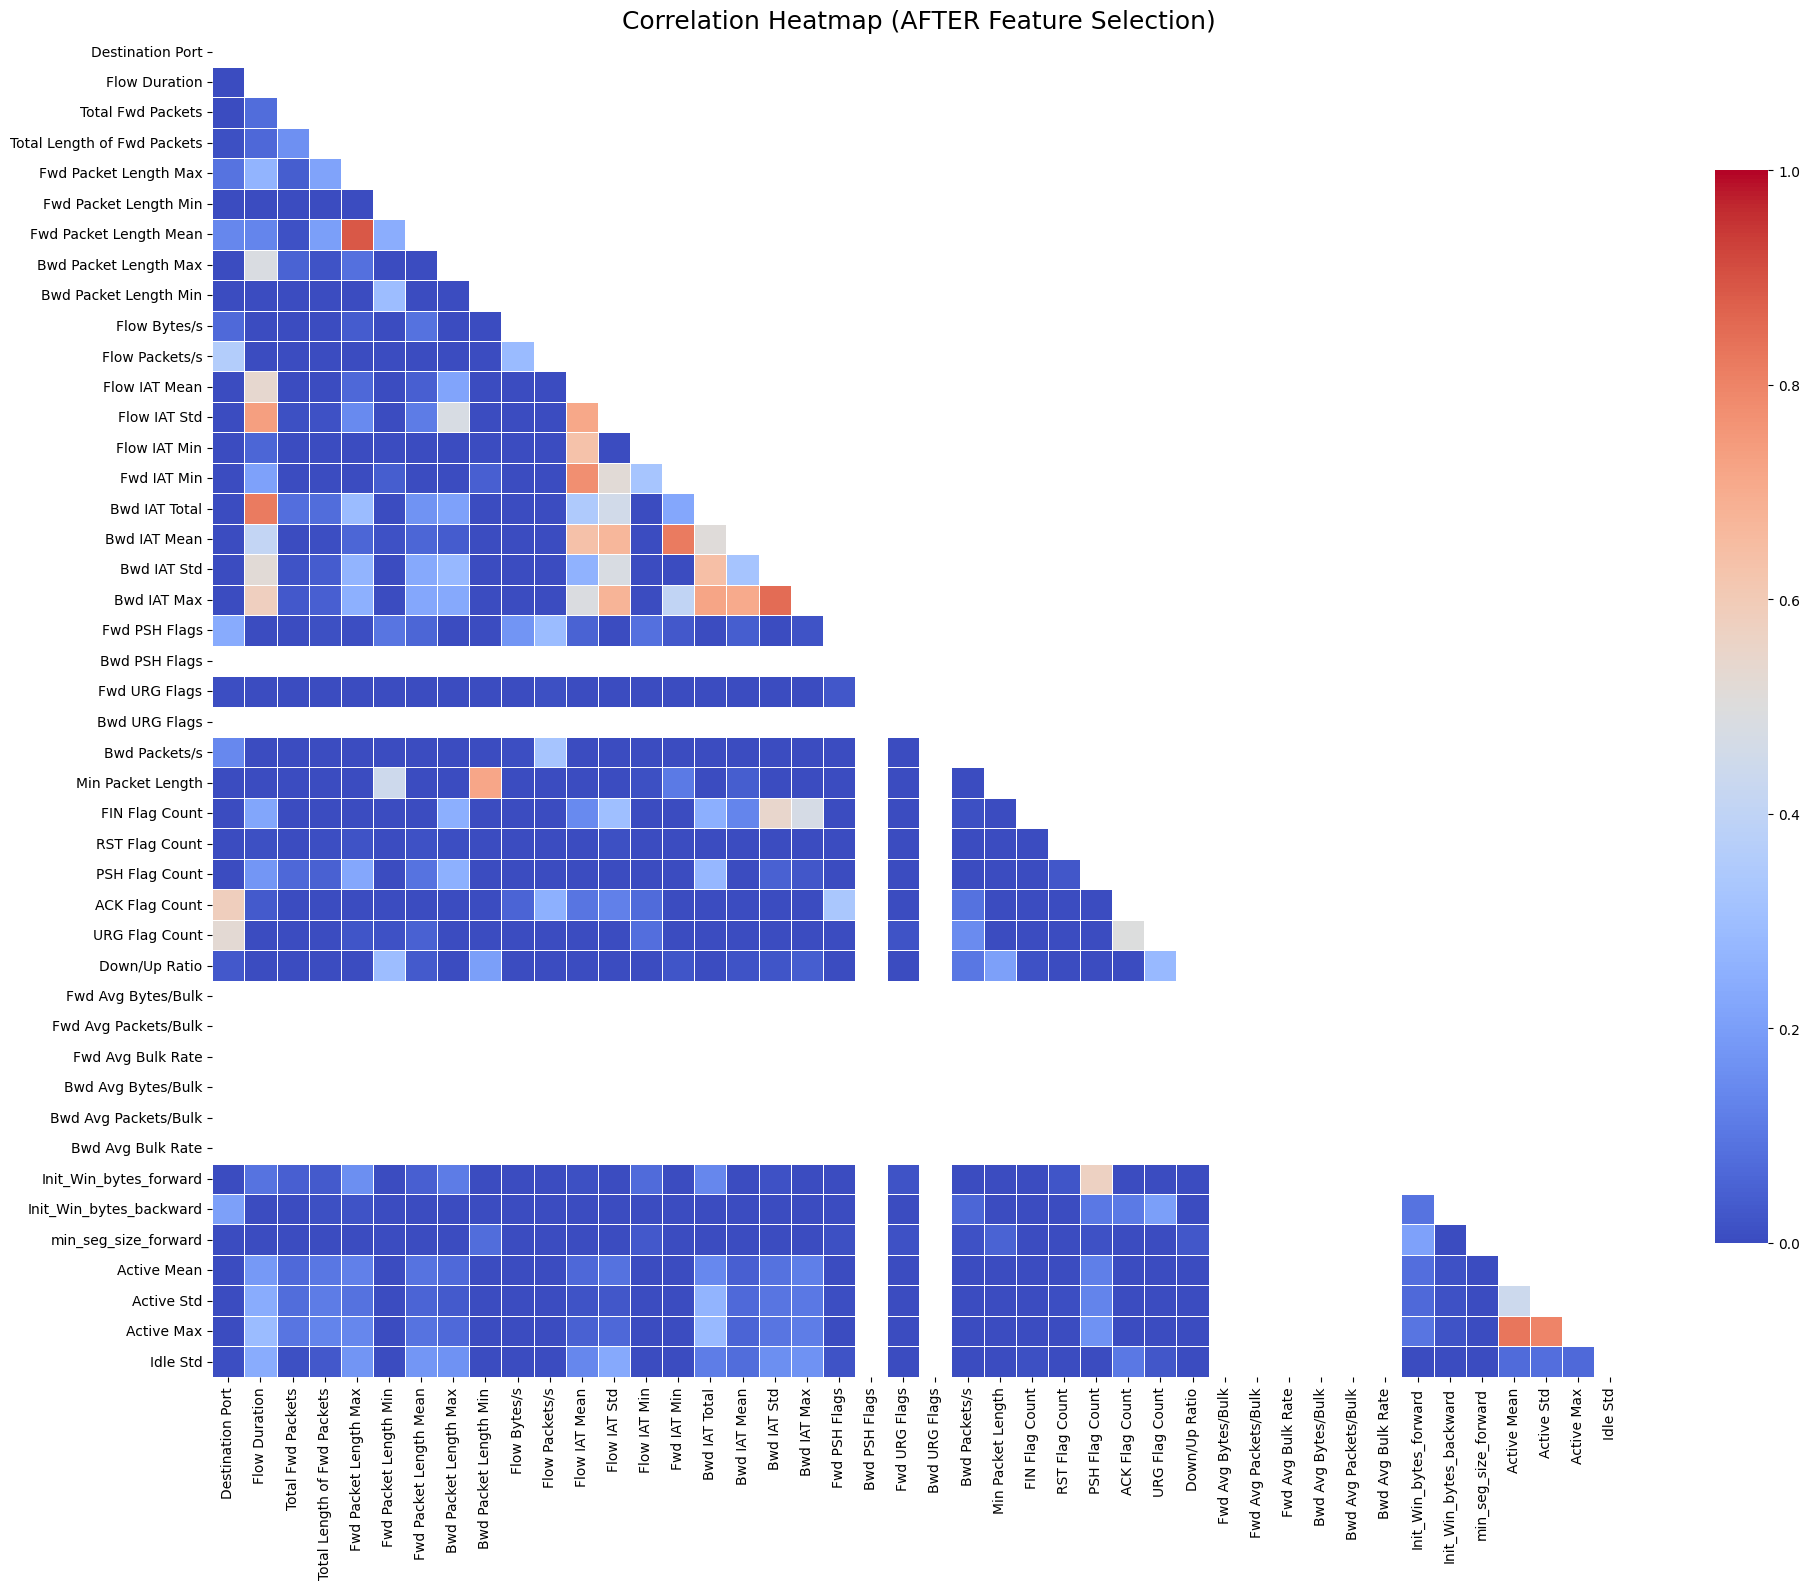

In [6]:
print("4. AFTER CLEANING & FEATURE SELECTION")

plot_correlation_heatmap(df_cleaned, title="Correlation Heatmap (AFTER Feature Selection)")

 5. ΣΥΓΚΕΝΤΡΩΤΙΚΑ BOXPLOTS (ΔΙΑΤΗΡΩΝΤΑΣ ΤΟ -1 ΩΣ ΕΓΚΥΡΗ ΤΙΜΗ)


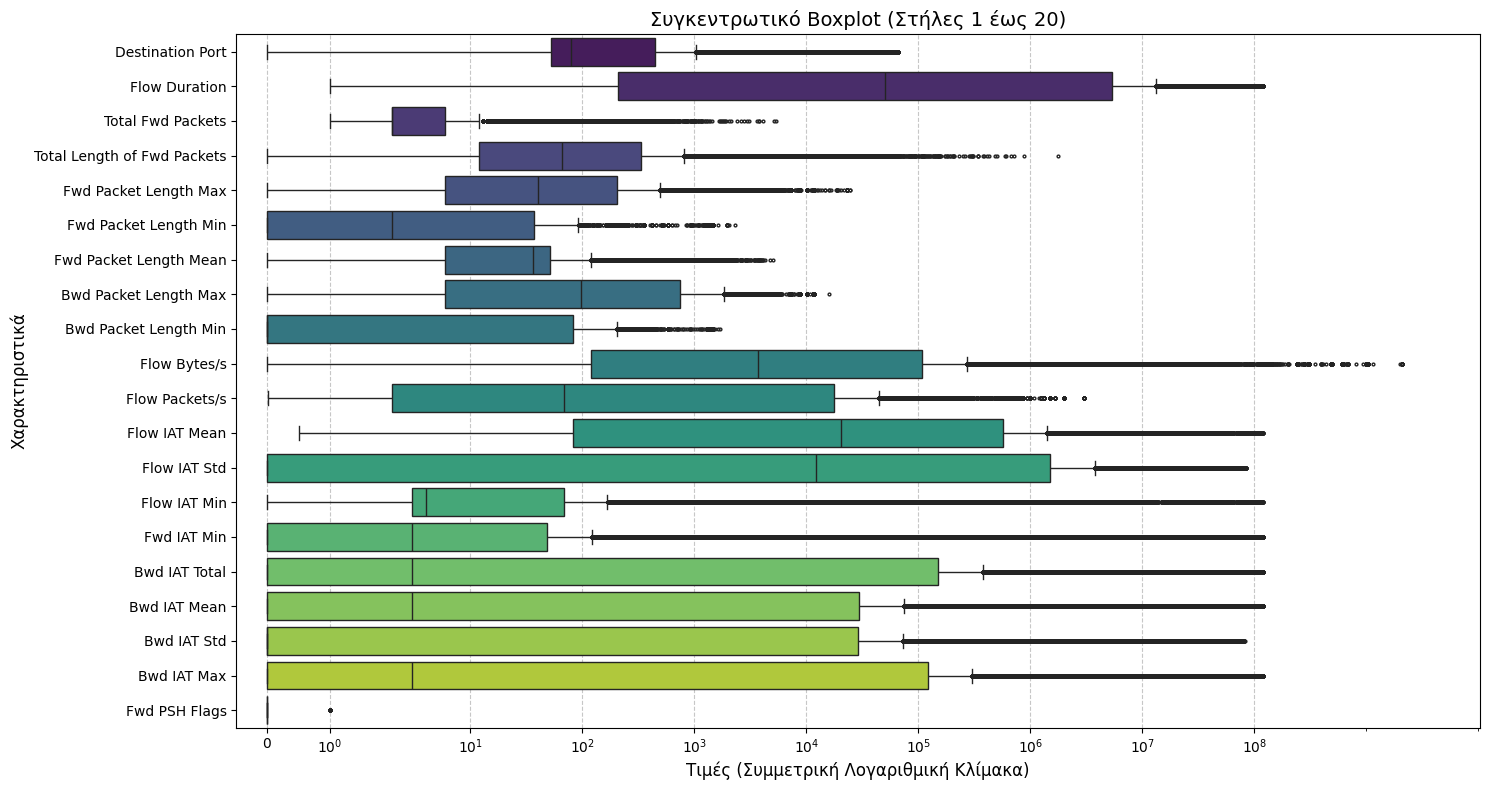

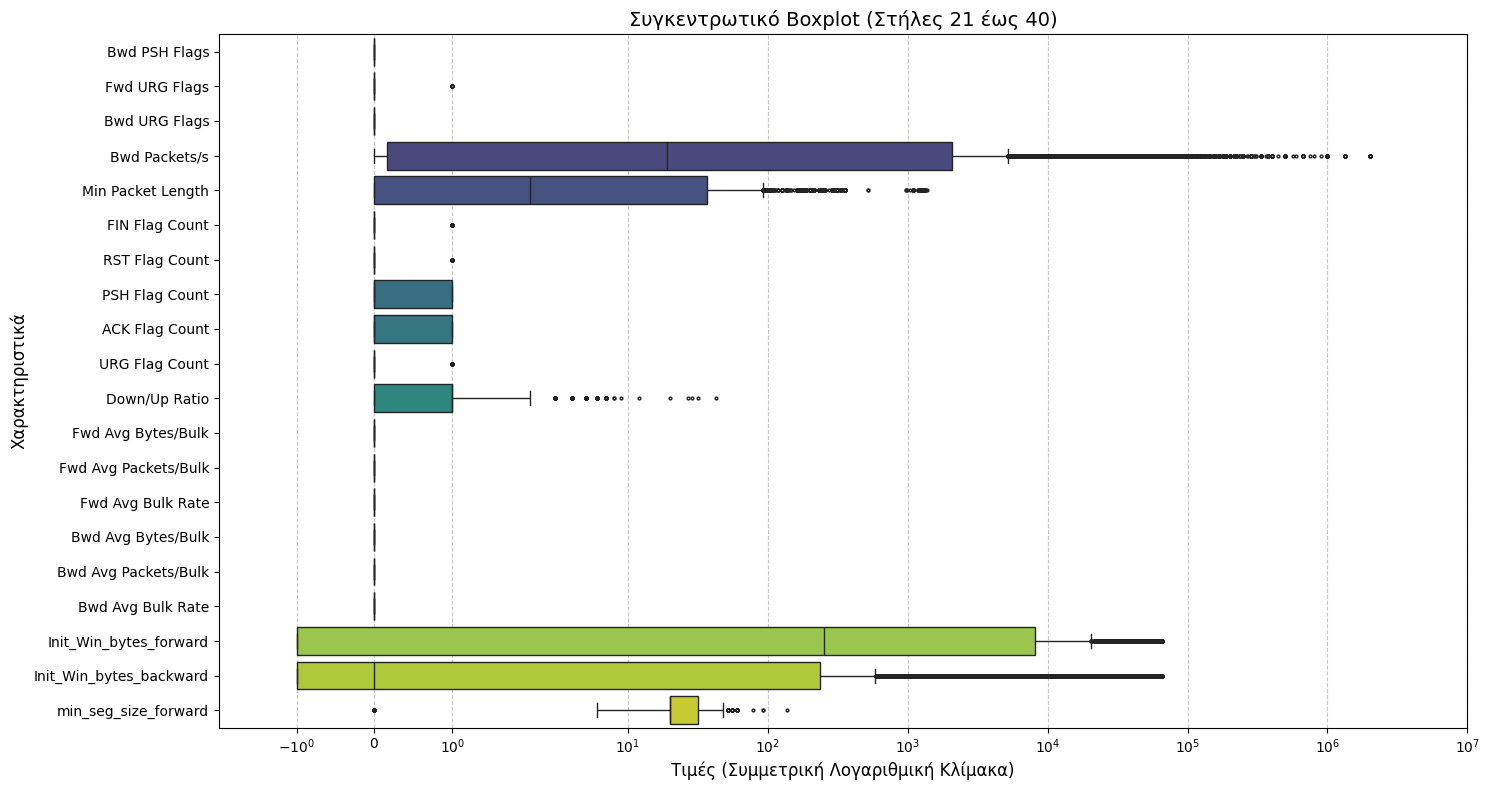

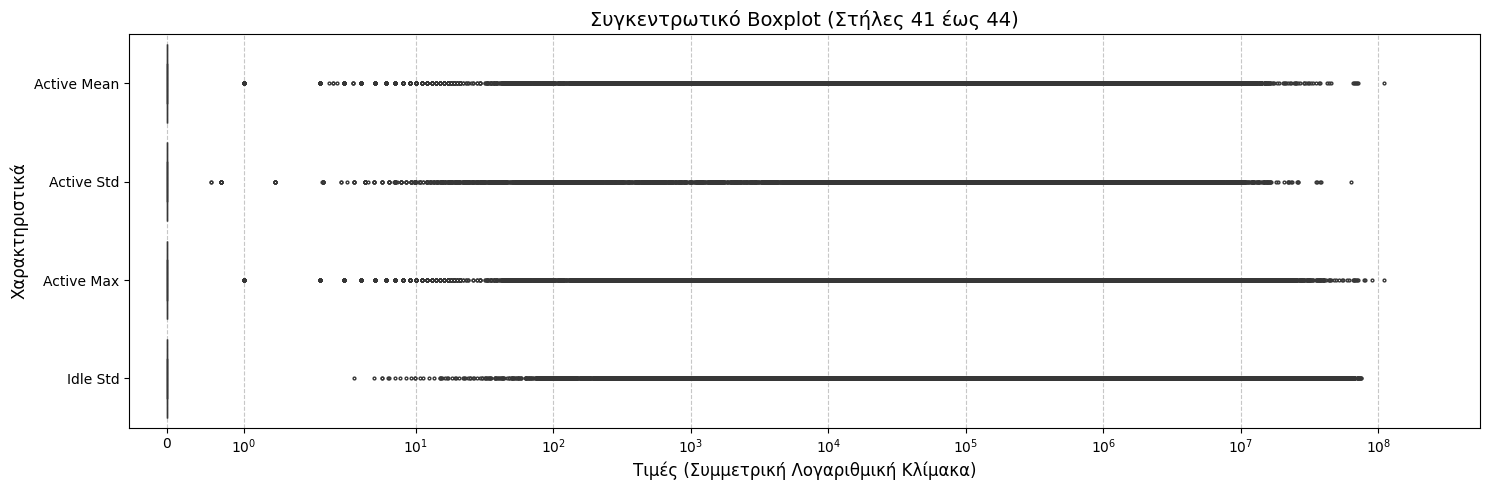

In [7]:
print("="*50)
print(" 5. ΣΥΓΚΕΝΤΡΩΤΙΚΑ BOXPLOTS (ΔΙΑΤΗΡΩΝΤΑΣ ΤΟ -1 ΩΣ ΕΓΚΥΡΗ ΤΙΜΗ)")
print("="*50)

numeric_cols = df_cleaned.select_dtypes(include=[np.number]).columns.tolist()

if len(numeric_cols) > 0:
    sample_size = min(500000, len(df_cleaned)) 
    df_plot = df_cleaned[numeric_cols].sample(n=sample_size, random_state=42) 

    chunk_size = 20
    for i in range(0, len(numeric_cols), chunk_size):
        chunk_cols = numeric_cols[i : i + chunk_size]
        
        fig_height = max(5, len(chunk_cols) * 0.4) 
        plt.figure(figsize=(15, fig_height))
        
        ax = sns.boxplot(data=df_plot[chunk_cols], orient='h', palette='viridis', fliersize=2)
        
        # Reverted to your original symlog default to keep the visual scale identical
        ax.set_xscale('symlog')
        
        chunk_min = df_plot[chunk_cols].min().min()
        chunk_max = df_plot[chunk_cols].max().max()
        
        left_limit = -2 if chunk_min < 0 else -0.5
        right_limit = chunk_max * 5 
        ax.set_xlim(left=left_limit, right=right_limit)
        
        # Added 1 (which is 10^0) back into the list!
        import matplotlib.ticker as ticker
        ticks = [-1, 0, 1, 10, 10**2, 10**3, 10**4, 10**5, 10**6, 10**7, 10**8]
        ax.set_xticks([t for t in ticks if left_limit <= t <= right_limit])
        
        plt.title(f'Συγκεντρωτικό Boxplot (Στήλες {i+1} έως {min(i+chunk_size, len(numeric_cols))})', fontsize=14)
        plt.xlabel('Τιμές (Συμμετρική Λογαριθμική Κλίμακα)', fontsize=12)
        plt.ylabel('Χαρακτηριστικά', fontsize=12)
        plt.grid(axis='x', linestyle='--', alpha=0.7)
        
        plt.tight_layout()
        plt.show()
else:
    print("Δεν βρέθηκαν αριθμητικές στήλες.")

In [8]:
# List of NEAR-0-VARIANCE binary flags to see what to drop
sparse_flags = ['Fwd PSH Flags', 'Fwd URG Flags', 'FIN Flag Count', 'RST Flag Count', 'URG Flag Count']

for flag in sparse_flags:
    if flag in df_cleaned.columns:
        print(f"\n--- Checking {flag} against Labels ---")
        # Create a cross-tabulation (frequency table)
        crosstab = pd.crosstab(df['Label'], df_cleaned[flag])
        print(crosstab)


--- Checking Fwd PSH Flags against Labels ---
Fwd PSH Flags                     0       1
Label                                      
BENIGN                      1973844  118491
Bot                            1948       0
DDoS                         127995       0
DoS GoldenEye                 10281       0
DoS Hulk                     172688       0
DoS Slowhttptest               4541     687
DoS slowloris                  3956    1429
FTP-Patator                    3986    1941
Heartbleed                        7       0
Infiltration                     15      20
PortScan                      90694       0
SSH-Patator                    3203      14
Web Attack � Brute Force       1470       0
Web Attack � Sql Injection       21       0
Web Attack � XSS                652       0

--- Checking Fwd URG Flags against Labels ---
Fwd URG Flags                     0   1
Label                                  
BENIGN                      2092255  80
Bot                            1948   

In [9]:
from sklearn.feature_selection import VarianceThreshold

print("--- DROPING NEAR ZERO VARIANCE ---")

# 1. Define our manual decisions based on Label analysis
useless_flags = ['Fwd URG Flags', 'RST Flag Count']
golden_flags = ['FIN Flag Count', 'URG Flag Count', 'Fwd PSH Flags']

# Drop the proven useless flags directly from df_cleaned
df_cleaned.drop(columns=[col for col in useless_flags if col in df_cleaned.columns], inplace=True)
print(f"Manually dropped useless flags: {useless_flags}")

# 2. Isolate the columns we want to test mathematically 
# (Excluding 'Label' and 'golden_flags')
cols_to_test = [col for col in df_cleaned.columns if col not in golden_flags and col != 'Label']

# 3. Run the automated sweep (threshold=0.0 drops ONLY perfectly flat lines)
selector = VarianceThreshold(threshold=0.0)
selector.fit(df_cleaned[cols_to_test])

# Find out which columns failed the variance check (the flat ones)
kept_auto_cols = df_cleaned[cols_to_test].columns[selector.get_support()]
dropped_auto_cols = list(set(cols_to_test) - set(kept_auto_cols))

# 4. Drop the flat columns directly from df_cleaned
df_cleaned.drop(columns=dropped_auto_cols, inplace=True)

print(f"Automatically dropped {len(dropped_auto_cols)} columns with exactly 0.0 variance:")
for col in dropped_auto_cols:
    print(f" - {col}")

--- DROPING NEAR ZERO VARIANCE ---
Manually dropped useless flags: ['Fwd URG Flags', 'RST Flag Count']
Automatically dropped 8 columns with exactly 0.0 variance:
 - Bwd Avg Bytes/Bulk
 - Fwd Avg Bulk Rate
 - Fwd Avg Packets/Bulk
 - Bwd PSH Flags
 - Fwd Avg Bytes/Bulk
 - Bwd Avg Packets/Bulk
 - Bwd URG Flags
 - Bwd Avg Bulk Rate


 6. FEATURE VS LABEL BOXPLOTS (SMART CAP STRATEGY)
Applying Smart Sampling to preserve rare attacks while reducing size...
Dataset successfully reduced to 194171 rows for rapid plotting.


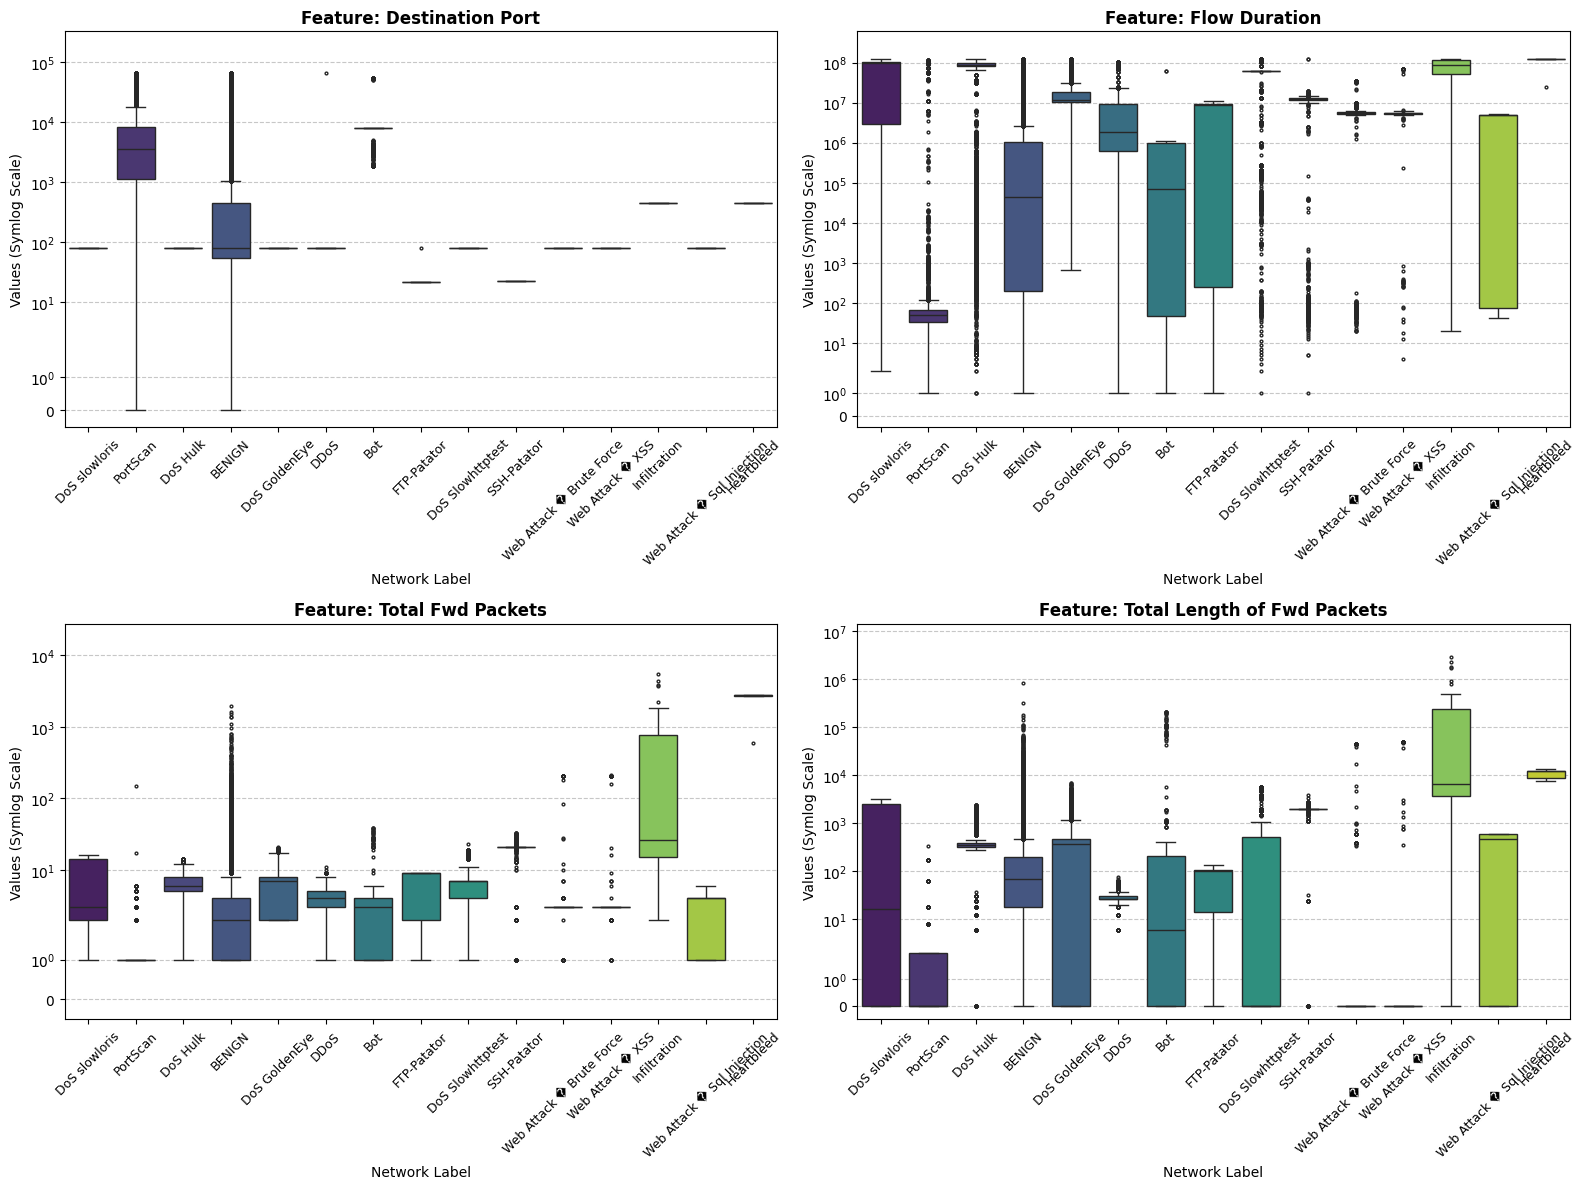

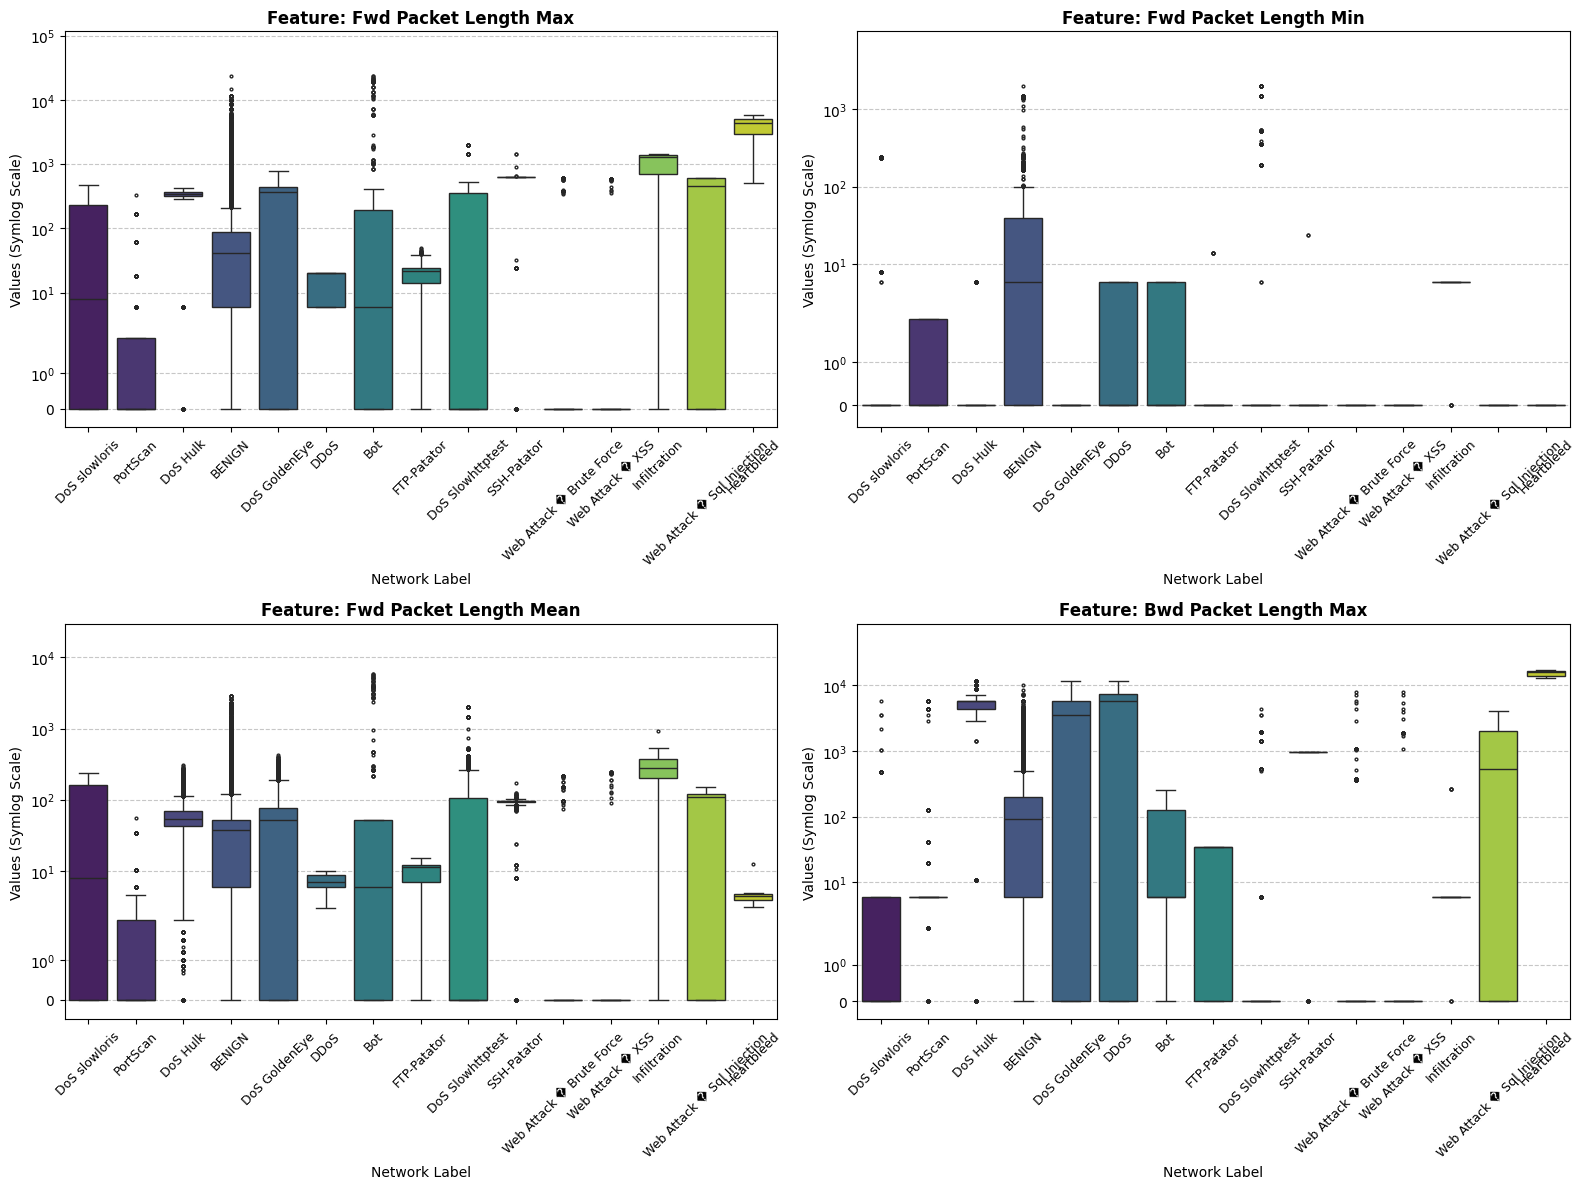

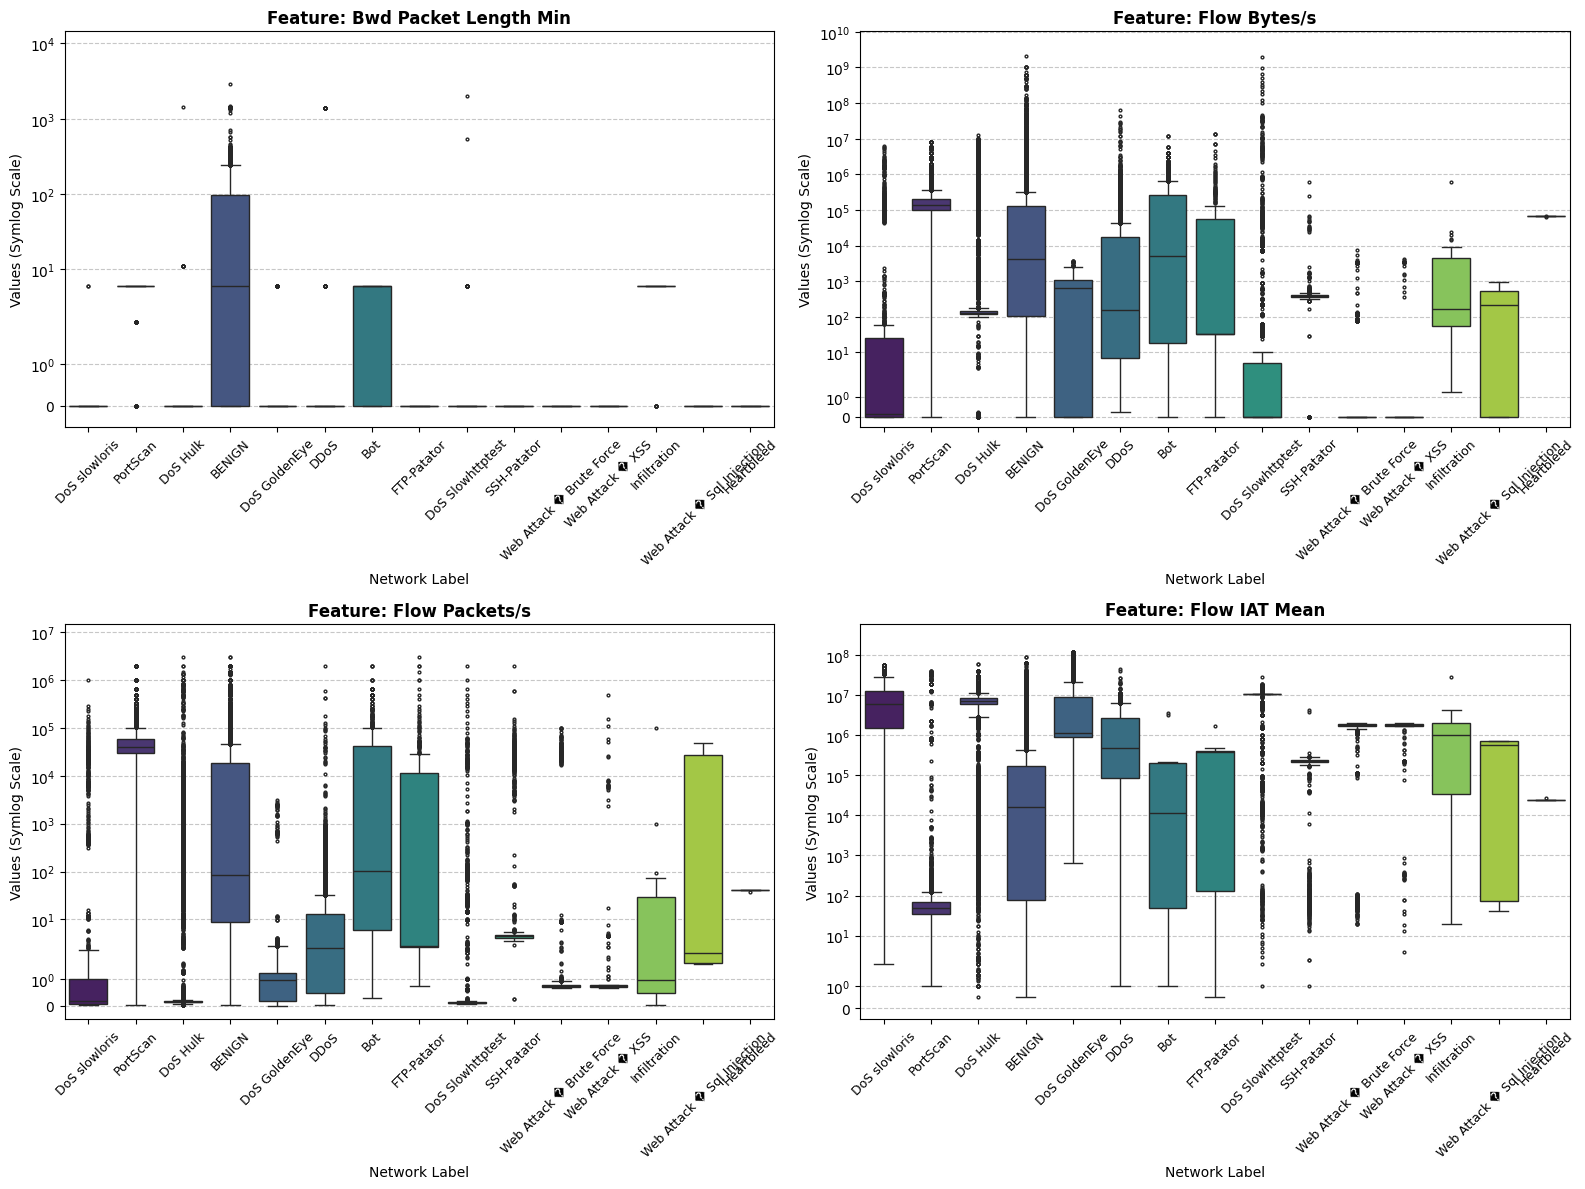

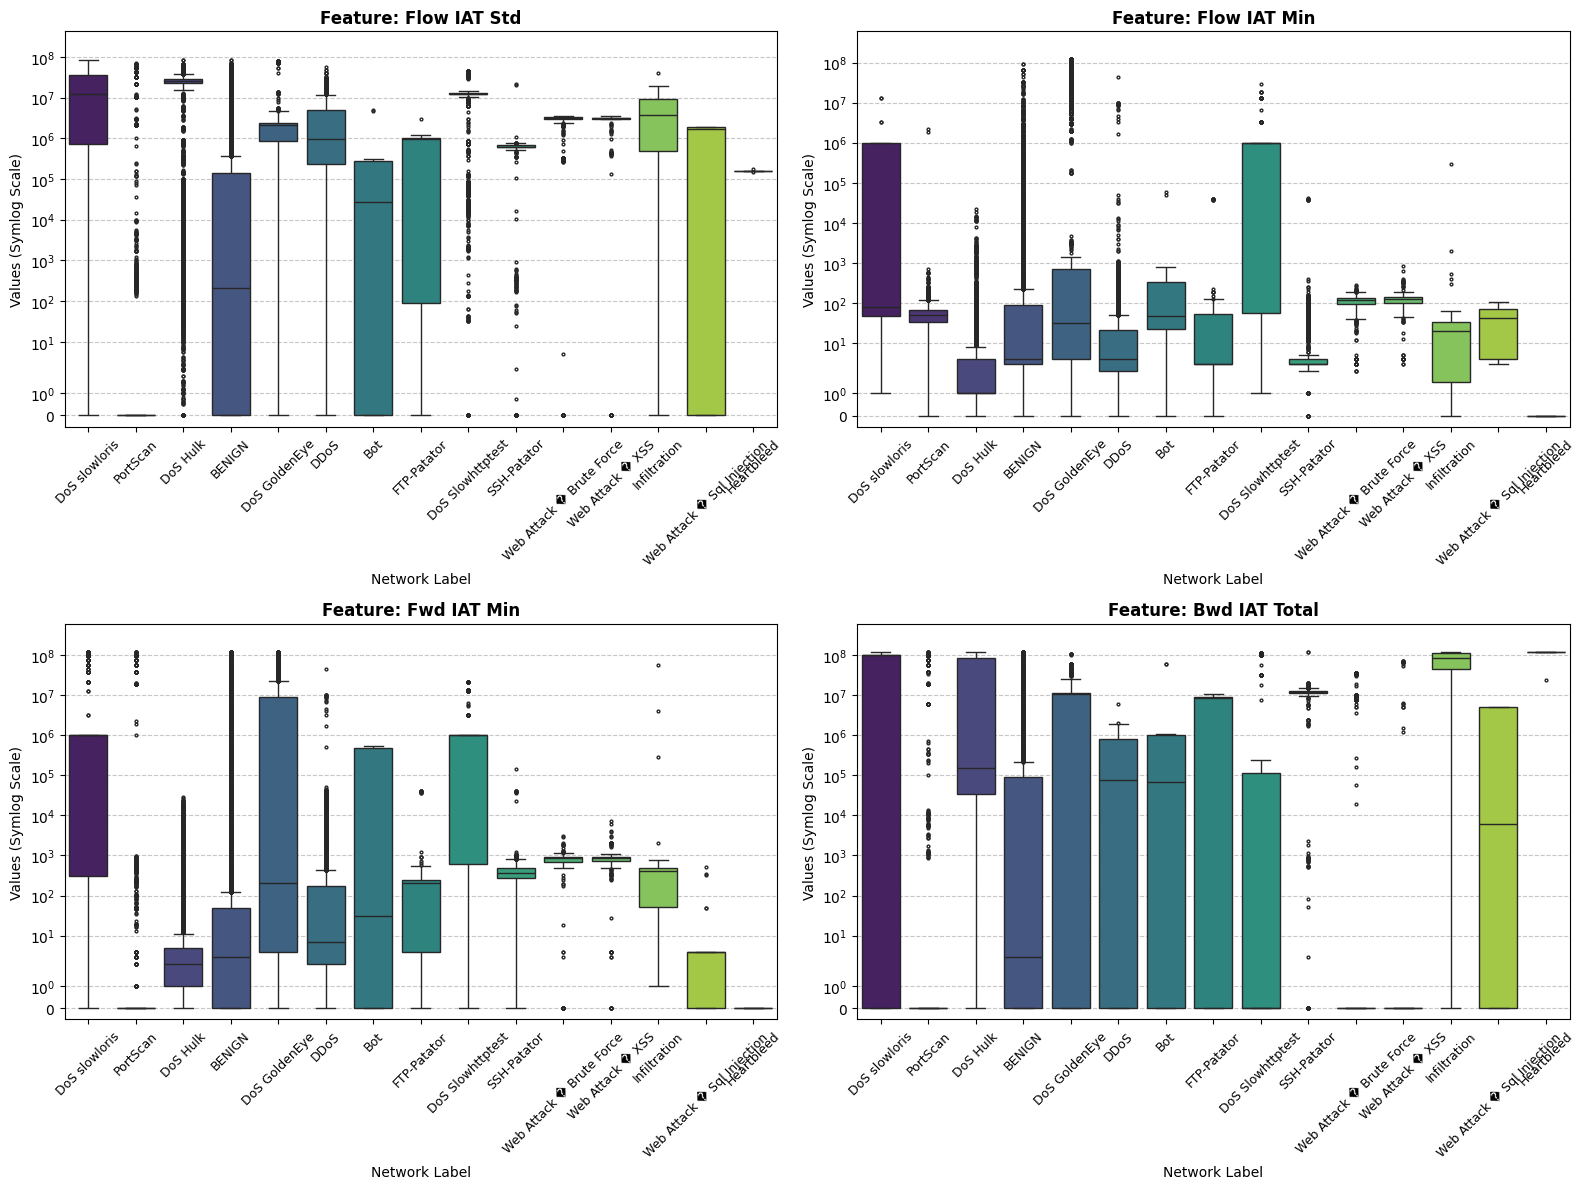

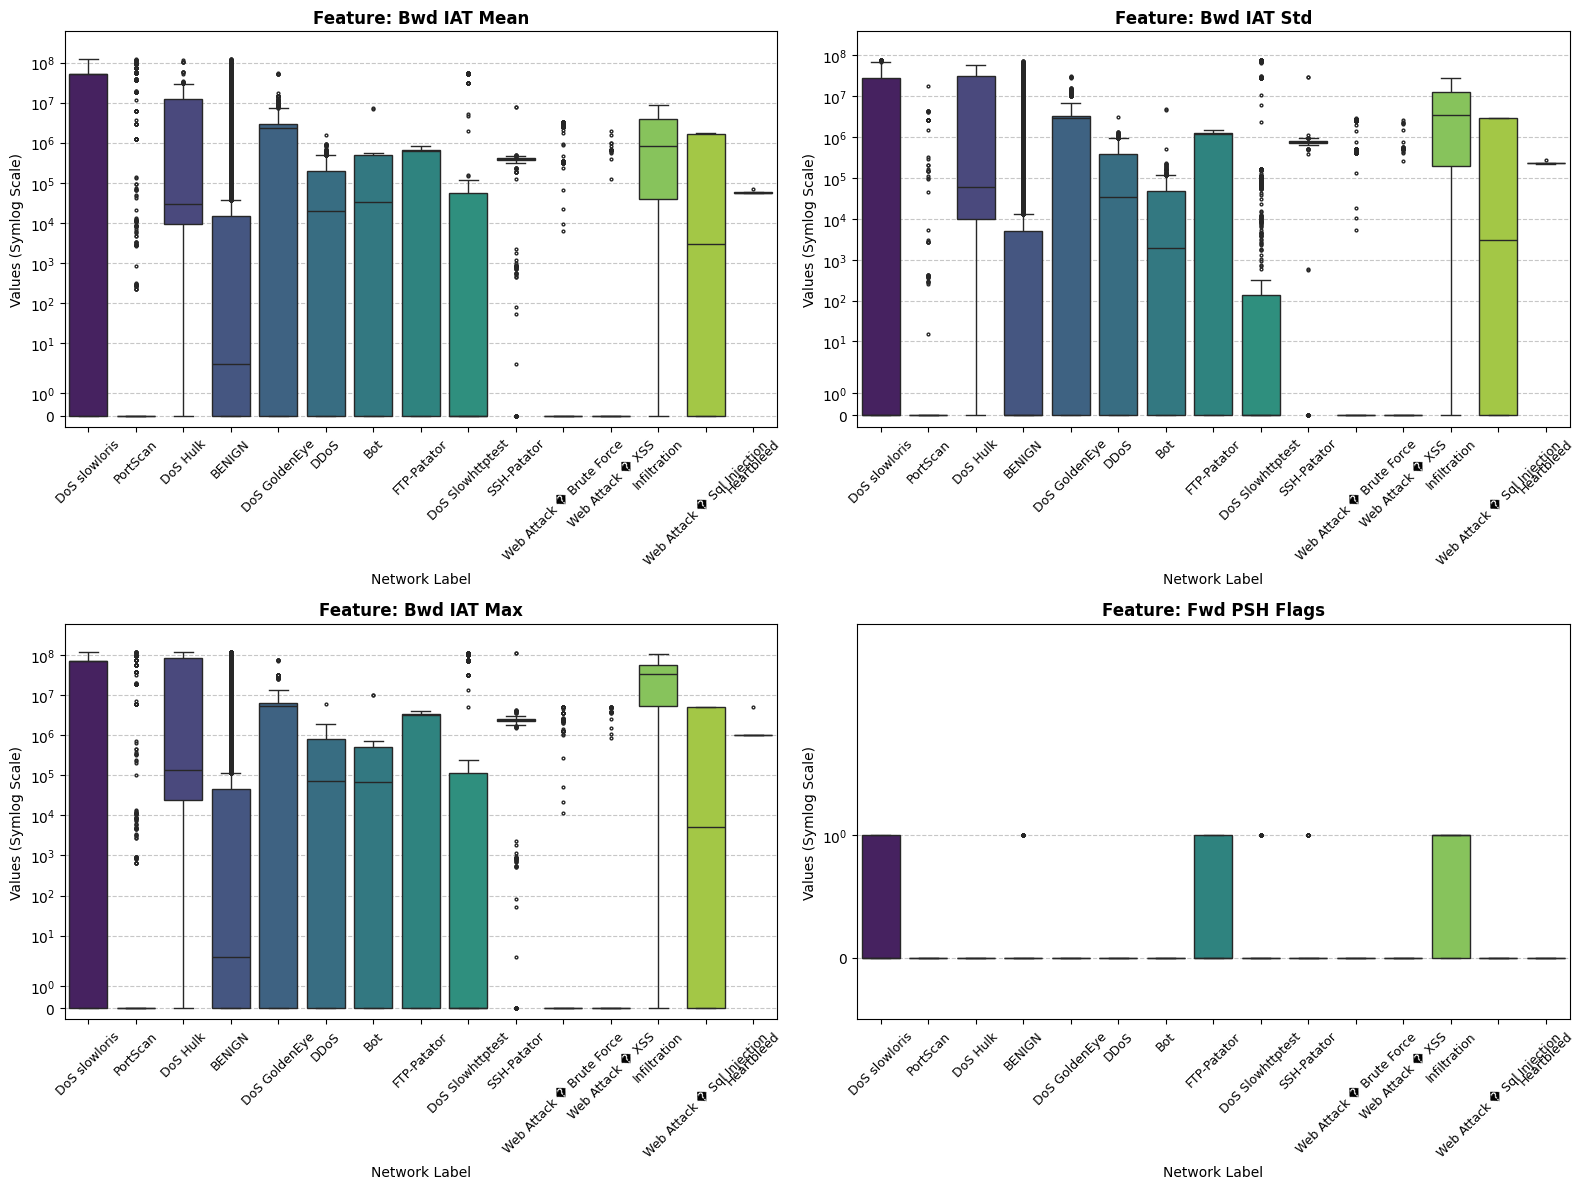

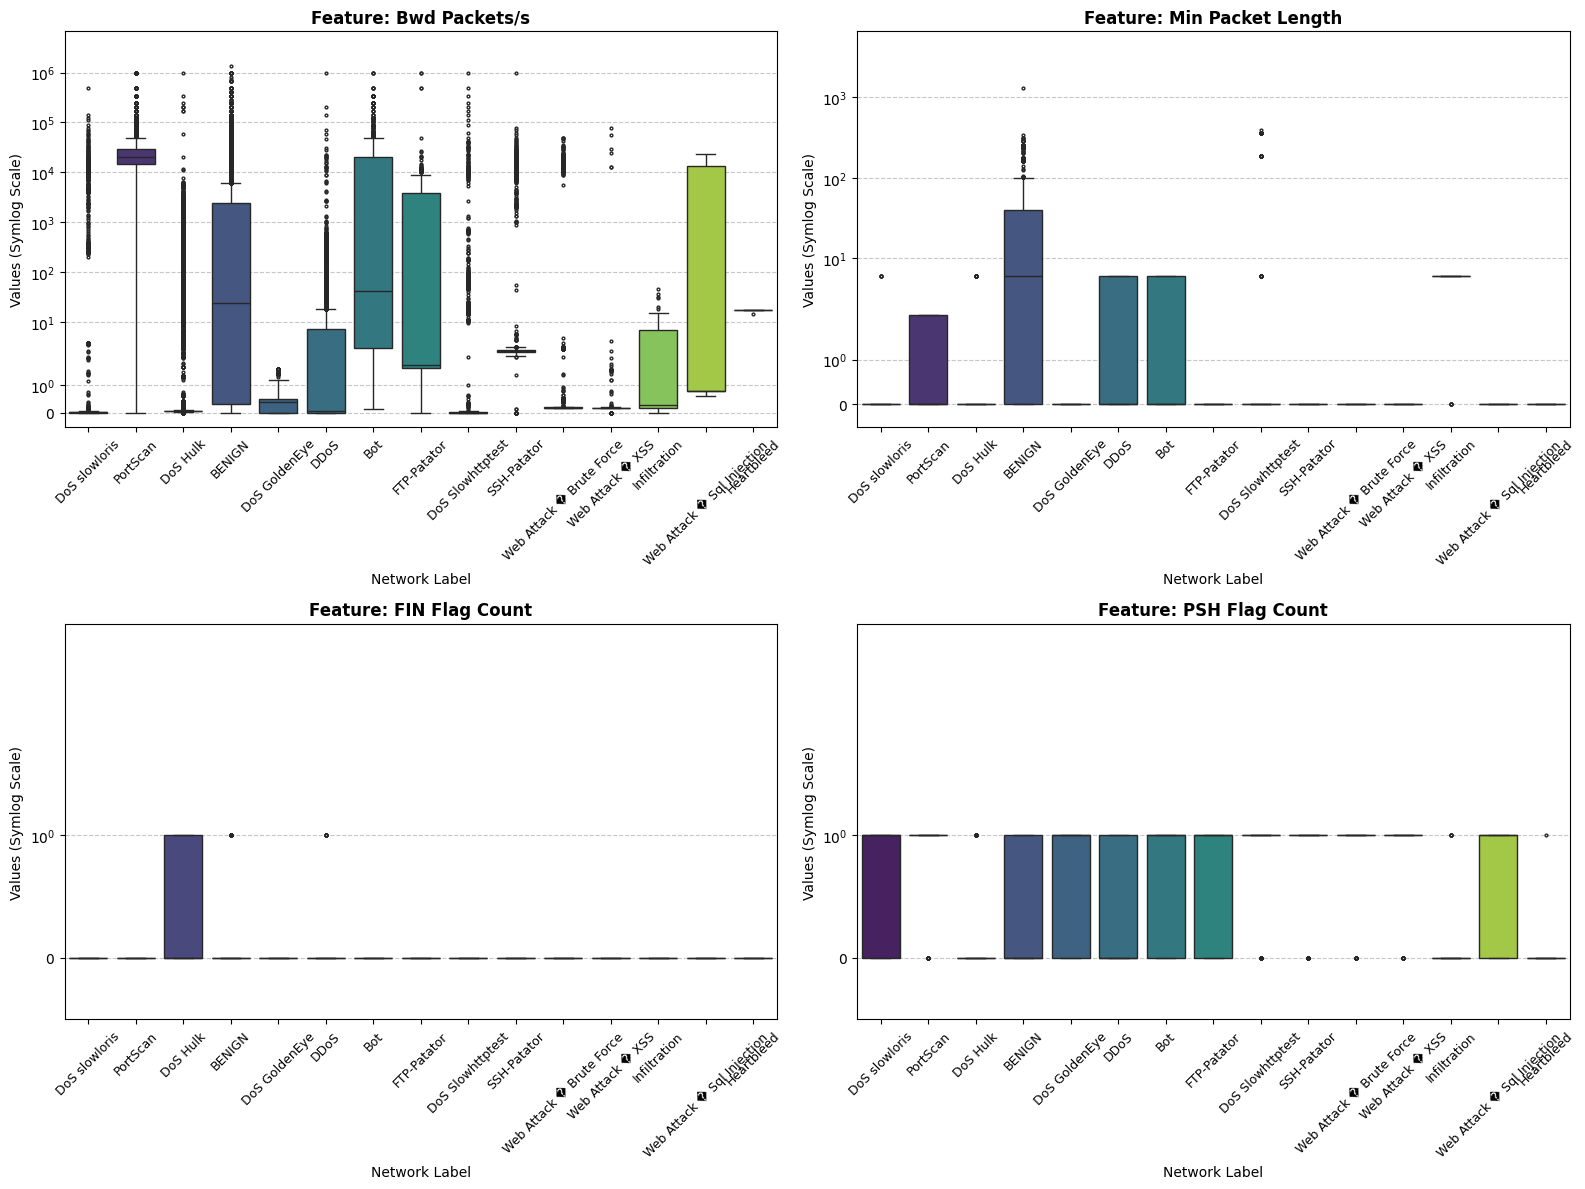

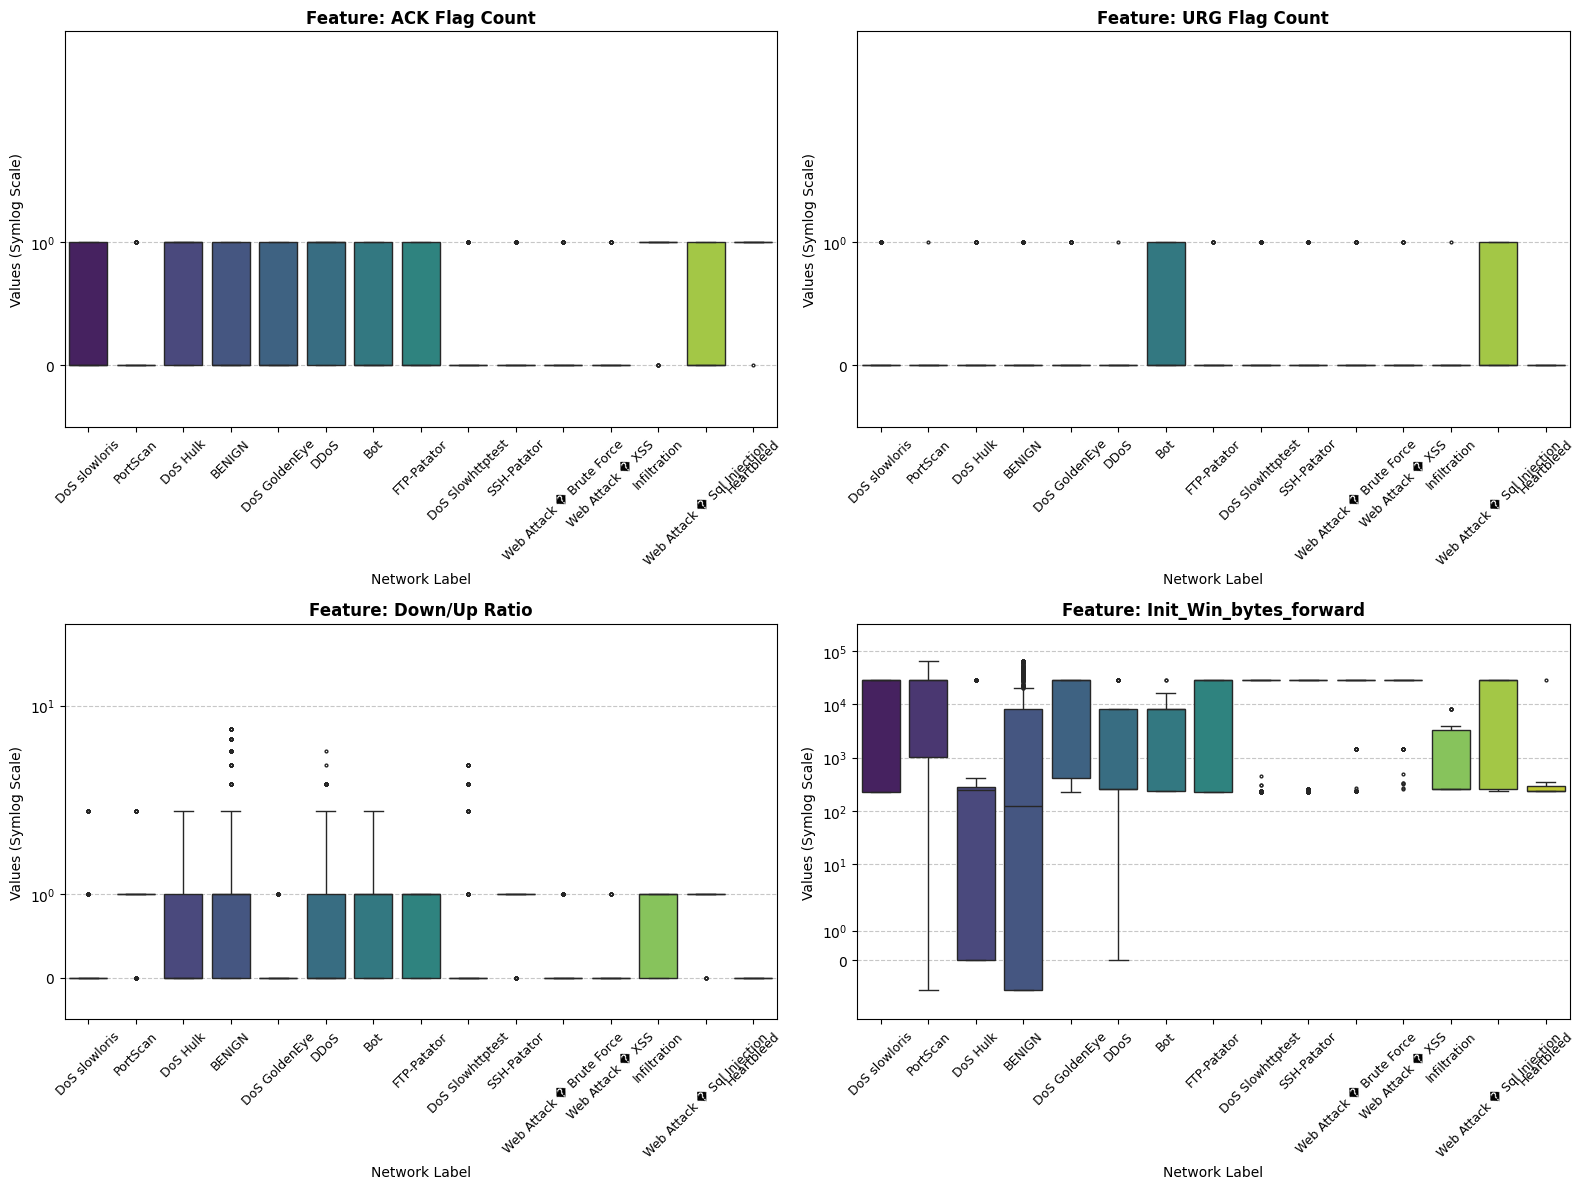

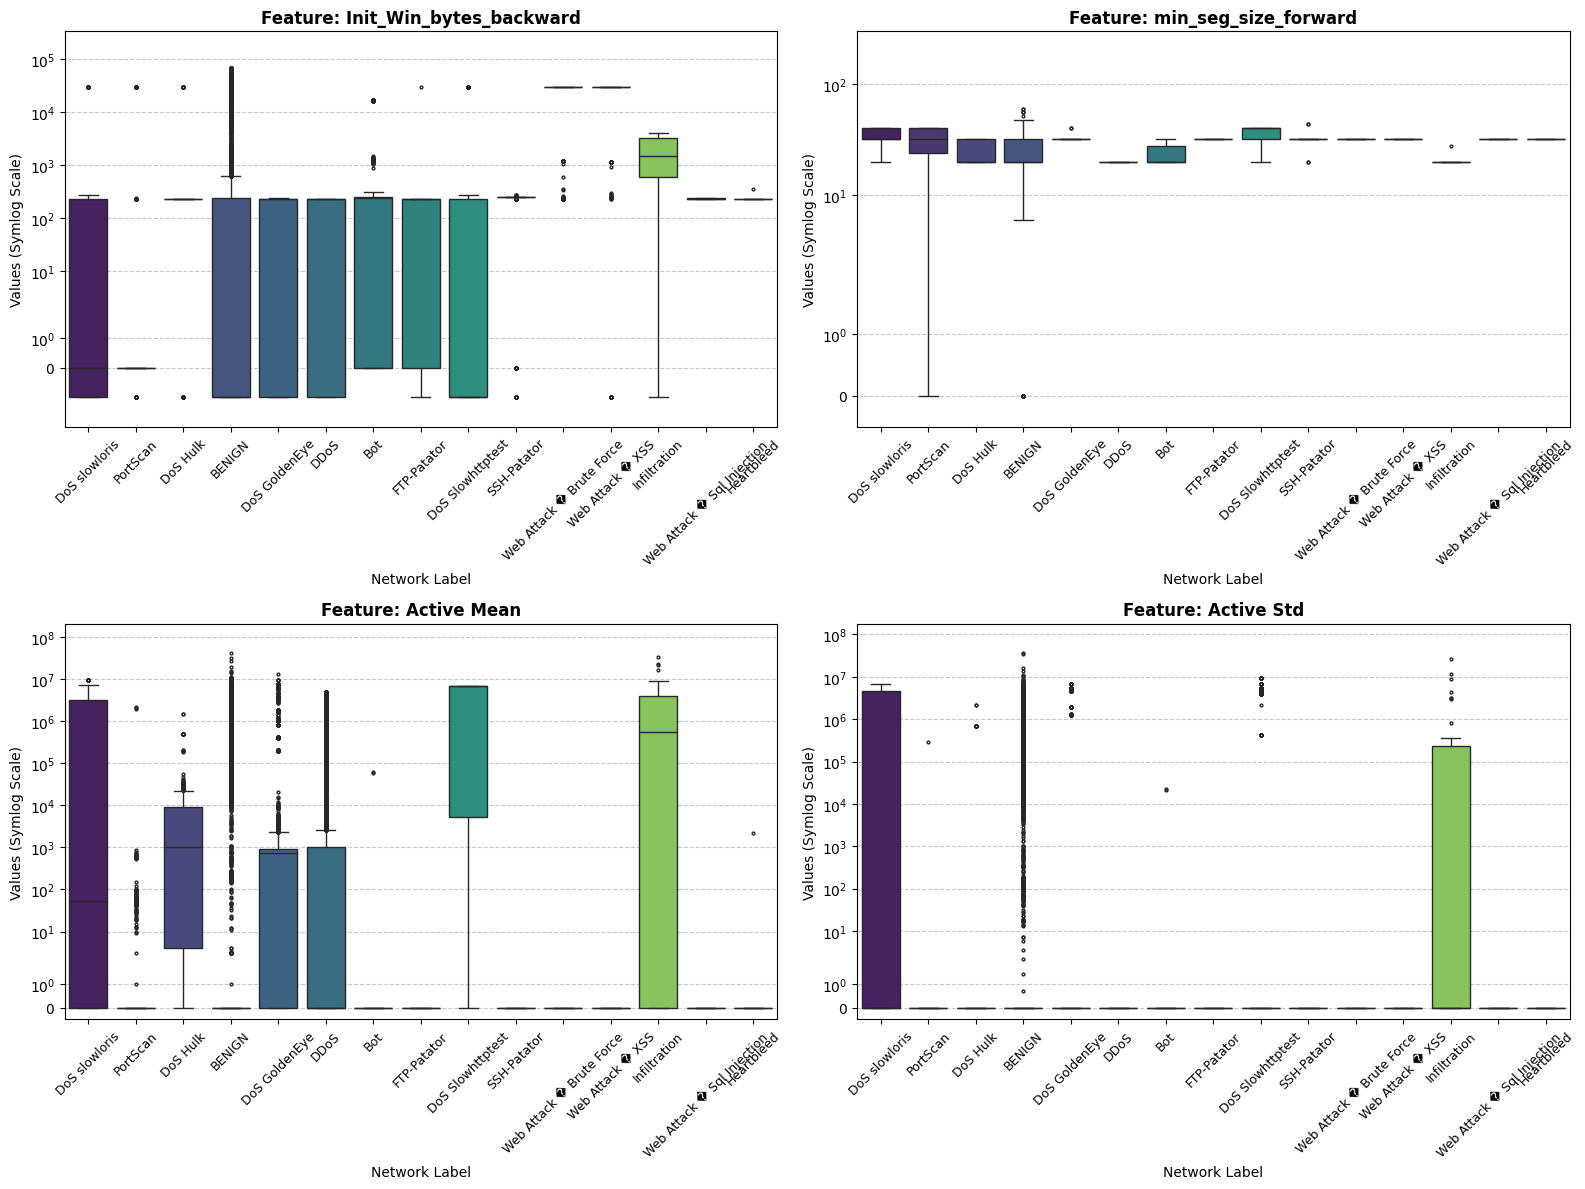

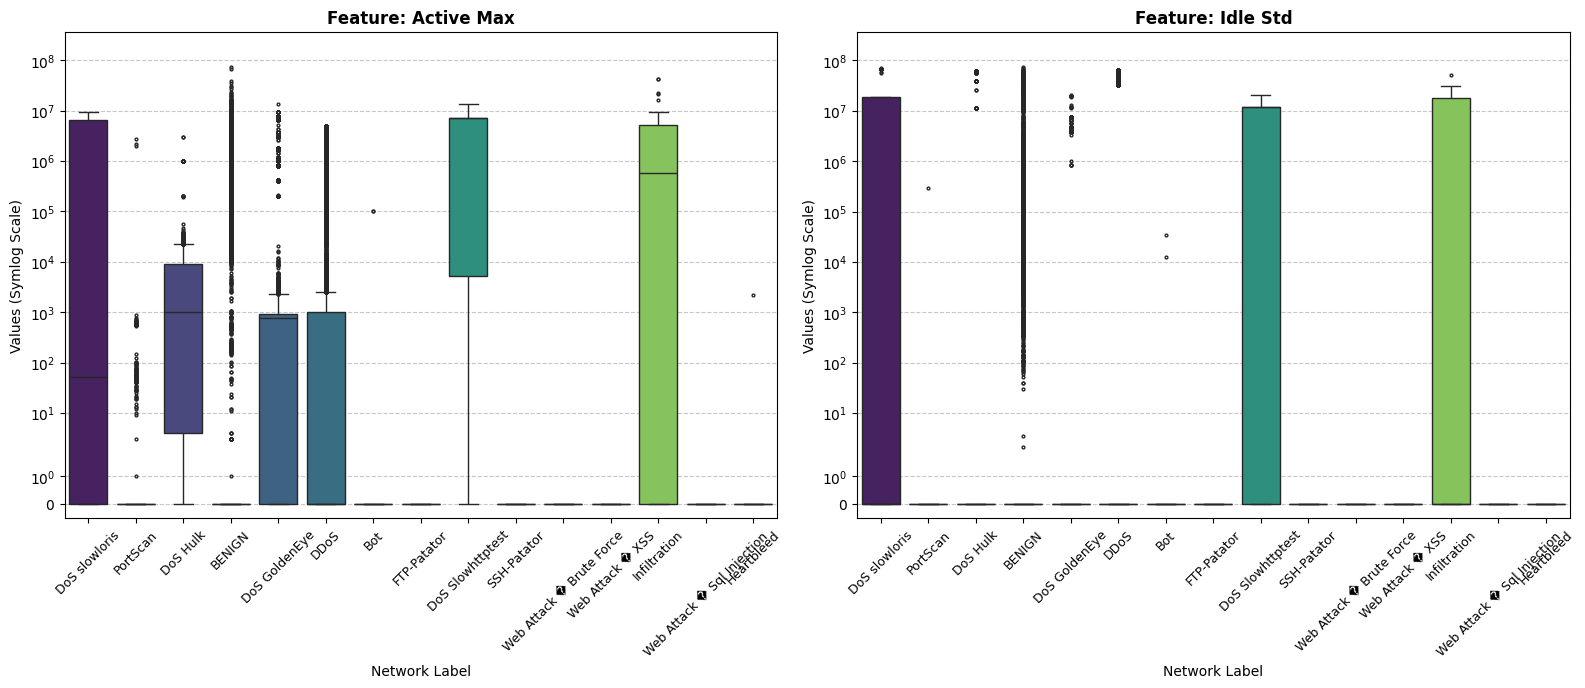

In [10]:
print("="*50)
print(" 6. FEATURE VS LABEL BOXPLOTS (SMART CAP STRATEGY)")
print("="*50)

if 'Label' in df_cleaned.columns:
    numeric_cols = [col for col in df_cleaned.columns if col != 'Label' and pd.api.types.is_numeric_dtype(df_cleaned[col])]
    
    if len(numeric_cols) > 0:
        print("Applying Smart Sampling to preserve rare attacks while reducing size...")
        
        # --- SMART CAP SAMPLING LOGIC ---
        cap_limit = 40000 
        sampled_chunks = []
        
        for label, group in df_cleaned.groupby('Label'):
            if len(group) > cap_limit:
                # If it's a massive class (like BENIGN), randomly downsample it to the cap
                sampled_chunks.append(group.sample(n=cap_limit, random_state=42))
            else:
                # If it's a rare attack, keep 100% of the rows to preserve its true shape
                sampled_chunks.append(group)
                
        # Re-assemble the smaller, mathematically accurate dataset
        df_plot = pd.concat(sampled_chunks).sample(frac=1, random_state=42) # frac=1 just shuffles it
        print(f"Dataset successfully reduced to {len(df_plot)} rows for rapid plotting.")
        # --------------------------------

        chunk_size = 4
        for i in range(0, len(numeric_cols), chunk_size):
            chunk_cols = numeric_cols[i : i + chunk_size]
            
            fig, axes = plt.subplots(2, 2, figsize=(16, 12))
            axes = axes.flatten() 
            
            for j, col in enumerate(chunk_cols):
                ax = axes[j]
                
                # Plot with hue and legend=False to prevent FutureWarnings
                sns.boxplot(x='Label', y=col, hue='Label', data=df_plot, ax=ax, palette='viridis', fliersize=2, legend=False)
                
                ax.set_yscale('symlog')
                
                # Dynamic limits so empty negative space is ignored
                col_min = df_plot[col].min()
                col_max = df_plot[col].max()
                
                bottom_limit = -2 if col_min < 0 else -0.5
                top_limit = col_max * 5 if col_max > 0 else 1
                
                ax.set_ylim(bottom=bottom_limit, top=top_limit)
                
                ax.set_title(f'Feature: {col}', fontsize=12, fontweight='bold')
                ax.set_ylabel('Values (Symlog Scale)', fontsize=10)
                ax.set_xlabel('Network Label', fontsize=10)
                
                ax.tick_params(axis='x', rotation=45, labelsize=9)
                ax.grid(axis='y', linestyle='--', alpha=0.7)
            
            for j in range(len(chunk_cols), 4):
                fig.delaxes(axes[j])
                
            plt.tight_layout()
            plt.show()
    else:
        print("No numerical columns found to plot.")
else:
    print("Error: 'Label' column not found.")

In [11]:
print("="*50)
print(" 7. OVERLAPPING FEATURE DROPPING")
print("="*50)

# List of features you want to drop
manual_drop_list = [
    'Fwd Packet Length Min',
    'Bwd Packet Length Min',  
    'Flow IAT Min',
    'PSH Flag Count',
    'ACK Flag Count',
    'Down/Up Ratio',
    'min_seg_size_forward',
    'Active Std',
    'Min Packet Length'
]

# Find which of these columns actually exist in the current cleaned dataframe
cols_to_drop = [col for col in manual_drop_list if col in df_cleaned.columns]
missing_cols = [col for col in manual_drop_list if col not in df_cleaned.columns]

if missing_cols:
    print(f"Note: The following columns were not found (they might be misspelled or already dropped):")
    for col in missing_cols:
        print(f" - {col}")

if cols_to_drop:
    # Drop the columns
    df_cleaned.drop(columns=cols_to_drop, inplace=True)
    print(f"\nSuccessfully dropped {len(cols_to_drop)} features.")
else:
    print("\nNo matching features found to drop.")

print(f"New dataset shape: {df_cleaned.shape}")

 7. OVERLAPPING FEATURE DROPPING

Successfully dropped 9 features.
New dataset shape: (2517883, 26)


 8. CLASS DISTRIBUTION (ΚΑΤΑΝΟΜΗ ΚΛΑΣΕΩΝ)


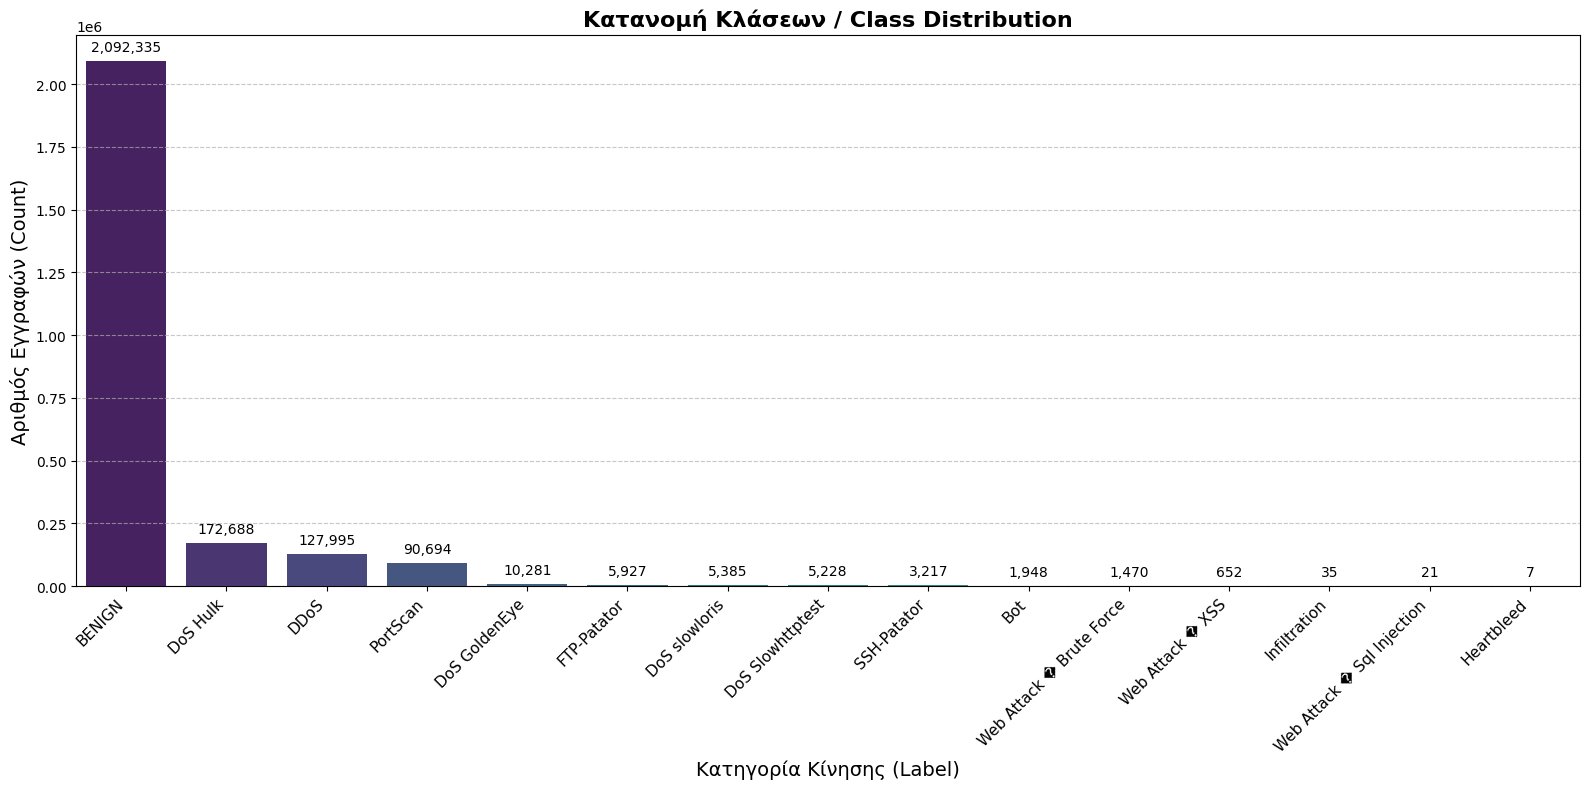


--- Ακριβής κατανομή ανά κλάση ---
Label
BENIGN                        2092335
DoS Hulk                       172688
DDoS                           127995
PortScan                        90694
DoS GoldenEye                   10281
FTP-Patator                      5927
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3217
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       35
Web Attack � Sql Injection         21
Heartbleed                          7


In [12]:
print("="*50)
print(" 8. CLASS DISTRIBUTION (ΚΑΤΑΝΟΜΗ ΚΛΑΣΕΩΝ)")
print("="*50)

# Check if 'Label' exists in the dataframe
if 'Label' in df_cleaned.columns:
    plt.figure(figsize=(16, 8))
    
    # Calculate the frequency of each class
    class_counts = df_cleaned['Label'].value_counts()
    
    # Create the bar plot
    # Using hue and legend=False to avoid Seaborn future warnings
    ax = sns.barplot(
        x=class_counts.index, 
        y=class_counts.values, 
        hue=class_counts.index, 
        palette='viridis', 
        legend=False
    )
    
    # Customize titles and labels
    plt.title('Κατανομή Κλάσεων / Class Distribution', fontsize=16, fontweight='bold')
    plt.xlabel('Κατηγορία Κίνησης (Label)', fontsize=14)
    plt.ylabel('Αριθμός Εγγραφών (Count)', fontsize=14)
    
    # Rotate x-axis labels so they are readable
    plt.xticks(rotation=45, ha='right', fontsize=11)
    
    # Add the exact number on top of each bar
    for p in ax.patches:
        height = p.get_height()
        # Only annotate if the bar has a height (avoids errors on empty classes)
        if not np.isnan(height) and height > 0:
            ax.annotate(f'{int(height):,}', 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='bottom', 
                        xytext=(0, 5), 
                        textcoords='offset points',
                        fontsize=10,
                        rotation=0)
    
    # Use a logarithmic scale if the imbalance is extreme (optional, uncomment if needed)
    # plt.yscale('log')
    # plt.ylabel('Αριθμός Εγγραφών (Log Scale)', fontsize=14)
    
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    # Print the raw text breakdown
    print("\n--- Ακριβής κατανομή ανά κλάση ---")
    print(class_counts.to_string())

else:
    print("Error: 'Label' column not found in df_cleaned.")

In [14]:
print("="*50)
print(" 9. EXPORTING FINAL DATASET")
print("="*50)

# Save as Parquet (Highly Recommended)
parquet_filename = "network_intrusion_cleaned.parquet"
df_cleaned.to_parquet(parquet_filename, index=False)
print(f"Saved successfully as {parquet_filename}")

# Save as CSV
#csv_filename = "network_intrusion_cleaned.csv"
#df_cleaned.to_csv(csv_filename, index=False)
#print(f"Saved successfully as {csv_filename}")

 9. EXPORTING FINAL DATASET
Saved successfully as network_intrusion_cleaned.parquet
